In [16]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scipy.interpolate
import statespace
import tqdm.auto as tqdm

from ocv_balancing import load_ne, load_pe, soc_to_ocv


In [17]:
def _make_interpolator(x, y):
    return scipy.interpolate.interp1d(
        x[::10],
        y[::10],
        kind="quadratic",
        fill_value="extrapolate",
        bounds_error=False,  # type: ignore
    )


class ECM(statespace.core.model.StateModel):
    def __init__(self, samples: int = 1):
        super().__init__(
            f=self.ecm_f,
            h=self.ecm_h,
            dim_x=3 * samples,
            dim_z=1 * samples,
            dim_u=1,
            dim_p=2 * samples,
        )
        self.samples = samples
        data = pl.read_csv("data/gitt_ecm_parameters.csv")
        self._Th = 0.1
        self._Cnom = 5.0
        luts = {}
        for d in ["Charge", "Discharge"]:
            for p in ["Open-circuit voltage / V", "R0 / Ohm", "R1 / Ohm", "Tau1 / s"]:
                mask = pl.col("Direction / 1") == d
                x, y = data.filter(mask).select(["State of Charge / 1", p]).to_numpy().T
                luts[f"{d} {p}"] = _make_interpolator(x, y)  # type: ignore

        self.luts = luts
        return

    def _hmix(self, h, c, d):
        a = (1 + h) / 2
        b = (1 - h) / 2
        return a * c + b * d

    def ecm_f(self, dt, x, u, p):
        soc, pol, hst = np.vsplit(x, 3)
        soh, sor = np.vsplit(p, 2)
        R1 = sor * self._hmix(
            hst,
            self.luts["Charge R1 / Ohm"](soc),
            self.luts["Discharge R1 / Ohm"](soc),
        )
        Tau1 = self._hmix(
            hst,
            self.luts["Charge Tau1 / s"](soc),
            self.luts["Discharge Tau1 / s"](soc),
        )

        d_soc = 0 * soc + u / (self._Cnom * 3600 * soh)
        d_pol = (u * R1 - pol) / Tau1
        d_hst = np.sign(u) * (np.sign(u) - hst) * d_soc / self._Th
        return x + dt * np.vstack([d_soc, d_pol, d_hst])

    def ecm_h(self, x, u, p):
        soc, pol, hst = np.vsplit(x, 3)
        soh, sor = np.vsplit(p, 2)

        R0 = sor * self._hmix(
            hst,
            self.luts["Charge R0 / Ohm"](soc),
            self.luts["Discharge R0 / Ohm"](soc),
        )

        Voc = self._hmix(
            hst,
            self.luts["Charge Open-circuit voltage / V"](soc),
            self.luts["Discharge Open-circuit voltage / V"](soc),
        )

        return Voc + pol + u * R0

In [18]:
ecm = ECM(samples=1)
ecm._Th = 0.4

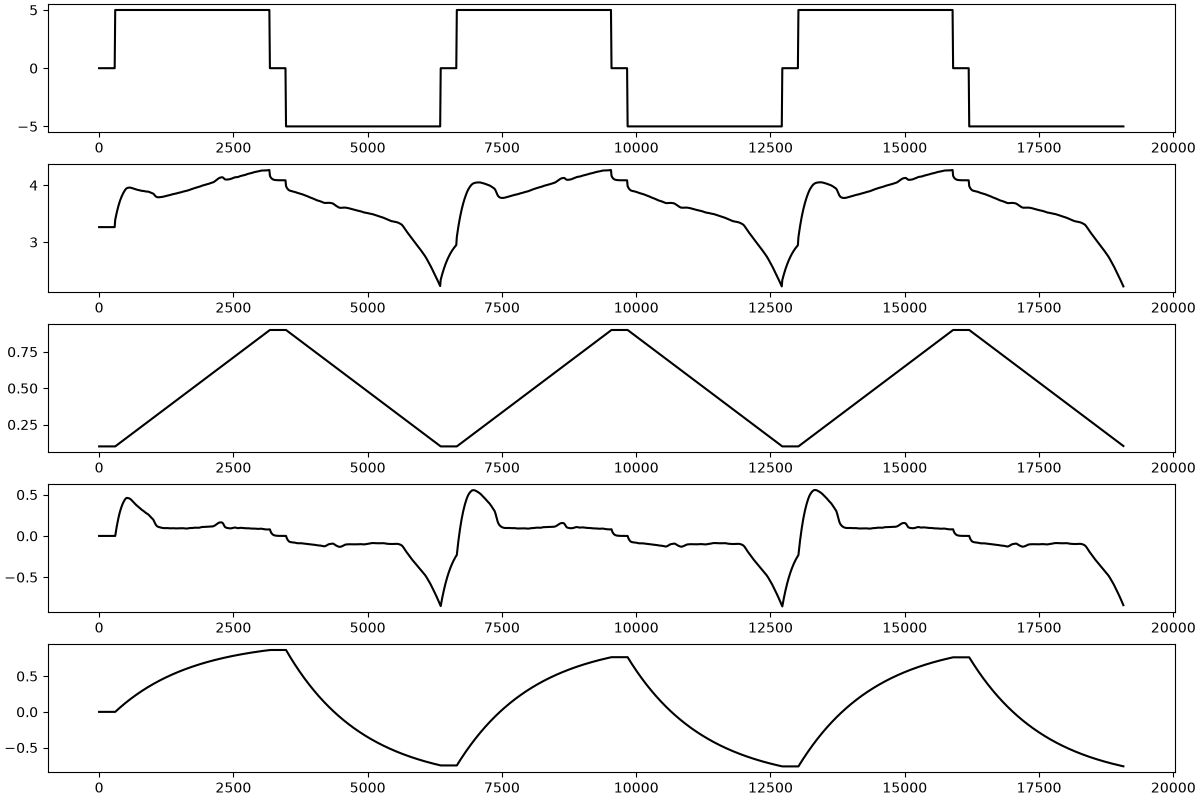

In [19]:
crate_pulse = 1.0
dod_pulse = 0.8
dt = 10.0
n_pulse = int((dod_pulse / crate_pulse) * 3600 / dt)
n_rest = int(300 / dt)
current = (
    np.concatenate(
        [np.zeros(n_rest), np.ones(n_pulse), np.zeros(n_rest), -np.ones(n_pulse)] * 3
    )
    * ecm._Cnom
)
t = np.arange(current.size) * dt
simulation = ecm.run(
    t,
    u=current[None, :],
    x0=np.array([0.1, 0.0, 0.0])[:, None],
    p=np.array([1.0, 1.0])[:, None],
)
voltage = simulation["z"][0, :]

fig, axs = plt.subplots(5, 1, constrained_layout=True, figsize=(12, 8))
axs[0].plot(t, current, color="k", label="Current / A")
axs[1].plot(t, voltage, color="k", label="Voltage / V")
axs[2].plot(t, simulation["x"][0, :], color="k", label="SOC / 1")
axs[3].plot(t, simulation["x"][1, :], color="k", label="Polarization / V")
axs[4].plot(t, simulation["x"][2, :], color="k", label="Hysteresis / 1")

  0%|          | 0/99 [00:00<?, ?it/s]

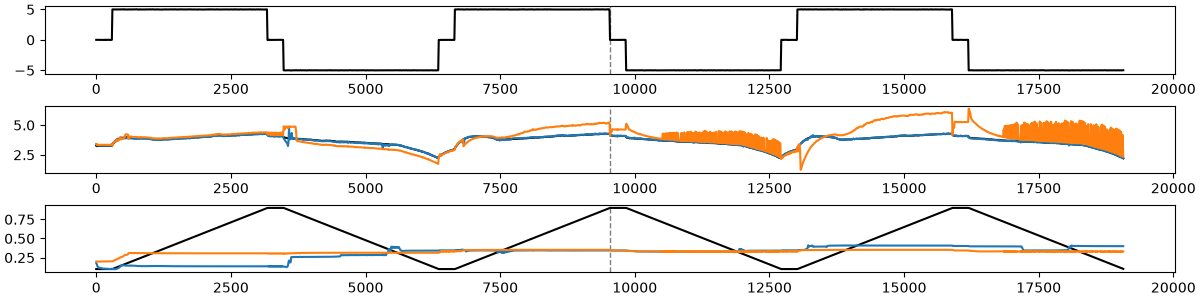

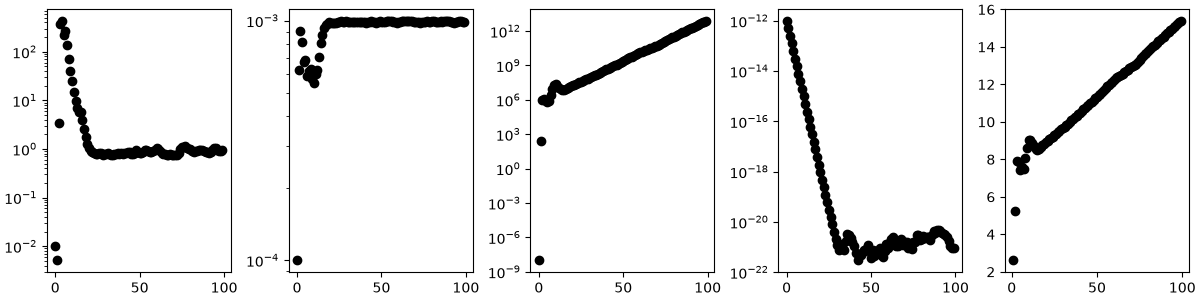

In [ ]:
Q = np.diag([1e-4, 1e-8, 1e-12])
P = np.diag([1e-2, 1e-3, 1e-4])
R = np.diag([1e-2])

u = current + np.random.normal(0, 1e-2, size=current.shape)
z = voltage + np.random.normal(0, 1e-2, size=voltage.shape)

fig1, axs1 = plt.subplots(3, 1, constrained_layout=True, figsize=(12, 3))
axs1[0].plot(t, u, color="k", label="Current / A")
axs1[1].plot(t, z, color="k", label="Voltage / V")
axs1[2].plot(t, simulation["x"][0, :], color="k", label="SOC / 1")

alpha = 0.5
beta = 0.5
k = t.size // 2
for ax in axs1:
    ax.axvline(t[-k], color="k", ls="--", lw=1, alpha=0.5)

fig2, axs2 = plt.subplots(1, 5, constrained_layout=True, figsize=(12, 3))
axs2[0].semilogy(0, R[0, 0], color="k", marker="o", ls="none")
axs2[1].semilogy(0, Q[0, 0], color="k", marker="o", ls="none")
axs2[2].semilogy(0, Q[1, 1], color="k", marker="o", ls="none")
axs2[3].semilogy(0, Q[2, 2], color="k", marker="o", ls="none")
maxiter = 100
for itr in tqdm.tqdm(range(1, maxiter)):
    ukf = statespace.FilterFactory().from_model(
        "UKF",
        ECM(samples=1),
        process_noise=Q,
        measurement_noise=R,
        initial_covariance=P,
        initial_state=np.array([0.2, 0.0, 0.0])[:, None],
    )
    est = ukf.run(
        t,
        u=u[None, :],
        z=z[None, :],
        p=np.array([0.8, 1.2])[:, None],
        progress=False,
    )
    residual = est["residual"][:, -k:]
    innovation = est["innovation"][:, -k:]
    gain = est["gain"][:, -k:]
    L = -np.mean(est["log_likelihood"][-k:])
    Q = (1 - alpha) * Q + alpha * (gain @ innovation.T @ innovation @ gain.T) / k  # type: ignore
    R = (1 - beta) * R + beta * (residual @ residual.T) / k  # type: ignore
    axs2[0].semilogy(itr, R[0, 0], color="k", marker="o", ls="none")
    axs2[1].semilogy(itr, Q[0, 0], color="k", marker="o", ls="none")
    axs2[2].semilogy(itr, Q[1, 1], color="k", marker="o", ls="none")
    axs2[3].semilogy(itr, Q[2, 2], color="k", marker="o", ls="none")
    axs2[4].plot(itr, L, color="k", marker="o", ls="none")
    if itr in [1, maxiter - 1]:
        axs1[1].plot(
            t, est["measurement"][0, :], label=f"Estimated SOC / 1 (itr={itr})"
        )
        axs1[2].plot(t, est["state"][0, :], label=f"Estimated SOC / 1 (itr={itr})")

In [37]:
est

{'time': array([0.000e+00, 1.000e+01, 2.000e+01, ..., 1.905e+04, 1.906e+04,
        1.907e+04], shape=(1908,)),
 'measurement': array([[3.41494263, 3.41318118, 3.3048274 , ..., 2.40149974, 4.17253584,
         2.34790169]], shape=(1, 1908)),
 'state': array([[ 1.99035083e-01,  1.97675526e-01,  1.97900593e-01, ...,
          3.24222090e-01,  3.31219487e-01,  3.29551432e-01],
        [-7.06077575e-05, -1.09793213e-04, -1.09102500e-01, ...,
         -1.00561350e+00,  7.60491891e-01, -1.06321664e+00],
        [-4.47286977e-07,  2.68239072e-05,  9.92304201e-05, ...,
         -9.99915596e-01, -9.99918529e-01, -9.99921352e-01]],
       shape=(3, 1908)),
 'log_likelihood': array([ -0.89551218,  -0.89761326, -15.60895726, ..., -15.28643786,
        -15.61630245, -15.23648854], shape=(1908,)),
 'innovation': array([[-6.70576387e-02, -9.56292165e-02,  1.67316922e+04, ...,
         -3.10699285e+05,  9.18070267e+05,  9.51897823e+04]],
       shape=(1, 1908)),
 'residual': array([[-0.13924457, -0.16